In [2]:
import duckdb 
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt


cnn = duckdb.connect() 

data_proyecciones =cnn.sql("select * from 'data/projections.parquet'").df()
data_proyecciones

,pid,youtube_id,title,vertical,pca3_x,pca3_y,pca3_z,umap_x,umap_y,umap_z,...,pca282_umap_z,tfidf_x,tfidf_y,tfidf_z,minilm_x,minilm_y,minilm_z,gemma2_x,gemma2_y,gemma2_z
0,eACj,-04_3RVWD7o,SOG Cutlass Machete,Hobbies & Leisure,0.084029,0.083468,-0.098645,2.628729,7.649654,8.933794,...,8.095982,8.042131,5.339788,4.705542,-0.446935,0.339699,6.123827,2.628729,7.649654,8.933794
1,ftCj,-0zrpo2QPPQ,star wars the clone wars episode 1 (on swedich...,Arts & Entertainment,0.058628,-0.071004,0.044223,4.768191,4.595020,10.474703,...,7.398306,4.107690,7.367922,5.488012,1.293200,2.898159,4.602725,4.768191,4.595020,10.474703
2,VDCj,-266lMiP8eI,혜민쌤의 스트럼스타일 전람회의 [기억의습작] 2,Arts & Entertainment,-0.096521,-0.051716,-0.150312,2.062567,0.483460,8.550847,...,9.215668,6.788684,5.161886,7.032432,-2.093462,2.646632,3.935264,2.062567,0.483460,8.550847
3,xNCj,oxAsv4jkrNQ,D.I.S.C.O MV - YeomJungHwa ft. T.O.P,Arts & Entertainment,-0.131939,-0.106059,0.011373,2.309696,-0.016760,7.857056,...,9.071431,7.564761,3.766407,5.983912,-1.133289,0.283881,4.243707,2.309696,-0.016760,7.857056
4,FaCj,ESohw5NGtBw,Magnum Shahntae Arabian Mare For Sale,Pets & Animals,0.012328,0.084364,-0.017940,-0.377057,4.960883,10.295608,...,7.262931,8.202357,5.171880,4.597318,-1.158605,-1.522751,6.396771,-0.377057,4.960883,10.295608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34783,4PI1,2XnicO002PU,Frederic Hanisch - First flight with Logo Xxtreme,Autos & Vehicles,0.020884,0.097152,0.022855,0.529085,7.863968,8.252274,...,7.763424,7.747014,6.661030,4.902669,1.775950,-0.872923,7.847099,0.529085,7.863968,8.252274
34784,wHI1,jj62fSuY4Vw,Mad Science- Gummy Bears,Pets & Animals,0.055566,0.010607,-0.070307,1.853542,6.509397,8.554582,...,7.409004,6.891010,3.832944,8.548945,1.008180,-0.156564,3.958434,1.853542,6.509397,8.554582
34785,1NI1,ZtG19JeNpGM,2014 統一全日本ダンス選手権大会 織田慶治 渡辺理子 引退,Arts & Entertainment,-0.109760,0.022214,0.125854,1.662258,3.562804,8.998517,...,8.810414,9.488696,3.640740,3.779671,-2.128705,-0.276928,4.625084,1.662258,3.562804,8.998517
34786,I5I1,ZzRv1Iq2g7A,Bubbly - Colbie Caillat (and 6 other songs in A),Arts & Entertainment,-0.171378,-0.086190,-0.168884,0.190951,0.659245,10.008394,...,8.740099,6.509918,4.325894,6.065674,-1.961603,2.228981,3.894453,0.190951,0.659245,10.008394


In [3]:
import plotly.express as px
import plotly.io as pio


def plot3d(name, data, point_size=2):
    fig = px.scatter_3d(data, x=f"{name}_x", y=f"{name}_y", z=f"{name}_z",
                        color="vertical", hover_name="title", opacity=0.6,
                        title=name, height=750,
                        color_discrete_sequence=px.colors.qualitative.Alphabet,
                        category_orders={"vertical": data["vertical"].value_counts().index.tolist()})
    fig.update_traces(marker_size=point_size)
    fig.update_layout(legend=dict(itemsizing="constant",   # símbolos grandes en la leyenda
                                  font_size=14,
                                  title_text="Categoría"))
    return fig

plot3d("pca282_umap", data_proyecciones)

In [4]:

plot3d("umap", data_proyecciones)

In [5]:
plot3d("pca3", data_proyecciones)

In [6]:
metricas = pd.read_csv("data/metricas_text.csv", index_col="proyeccion")
metricas


,trustworthiness,silhouette_vertical,knn_acc_vertical,ARI_kmeans,NMI_kmeans
proyeccion,,,,,
pca3,0.830,-0.160,0.638,0.121,0.323
umap,0.957,-0.163,0.764,0.143,0.360
pca282_umap,0.959,-0.171,0.769,0.155,0.377
original_768,NaN,0.008,0.793,0.137,0.346
baseline_mayoria,NaN,NaN,0.346,NaN,NaN


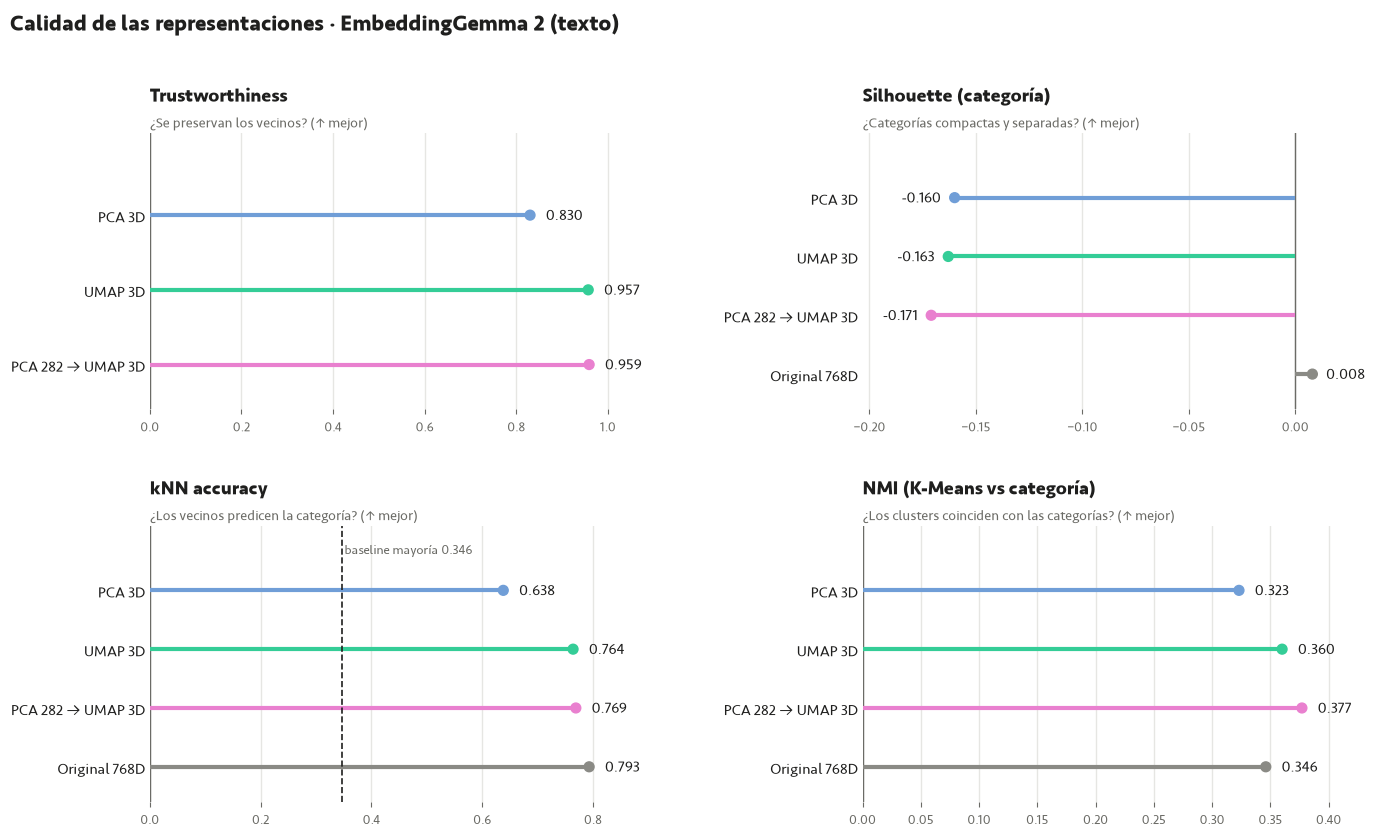

In [7]:
# Visualización: 4 métricas × modelo (sin ARI)
COLORS = {"pca3": "#709ed7", "umap": "#34cd97", "pca282_umap": "#e980cf", "original_768": "#8a8a85"}
NAMES  = {"pca3": "PCA 3D", "umap": "UMAP 3D", "pca282_umap": "PCA 282 → UMAP 3D", "original_768": "Original 768D"}
PANELS = [
    ("trustworthiness",     "Trustworthiness",            "¿Se preservan los vecinos? (↑ mejor)"),
    ("silhouette_vertical", "Silhouette (categoría)",     "¿Categorías compactas y separadas? (↑ mejor)"),
    ("knn_acc_vertical",    "kNN accuracy",               "¿Los vecinos predicen la categoría? (↑ mejor)"),
    ("NMI_kmeans",          "NMI (K-Means vs categoría)", "¿Los clusters coinciden con las categorías? (↑ mejor)"),
]
INK, MUTED, GRID = "#1f1f1e", "#6b6b66", "#e6e6e3"
plt.rcParams["font.family"] = "Seravek"
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), facecolor="white")
for ax, (col, title, subtitle) in zip(axes.flat, PANELS):
    s = metricas.loc[[m for m in COLORS if m in metricas.index], col].dropna()
    ypos = np.arange(len(s))[::-1]                       # primer modelo arriba
    colors = [COLORS[m] for m in s.index]
    ax.hlines(ypos, 0, s.values, color=colors, linewidth=3, zorder=3)   # tallo
    ax.scatter(s.values, ypos, color=colors, s=50, zorder=4)           # cabeza


    # rango del eje: incluye el 0 y deja espacio para las etiquetas de valor
    lo, hi = min(0, s.min()), max(0, s.max())
    pad = (hi - lo) * 0.18
    ax.set_xlim(lo - (pad if lo < 0 else 0), hi + pad)

    # valor al final de cada barra
  
    for yy, (m, v) in zip(ypos, s.items()):
        ax.text(v + (pad * 0.2 if v >= 0 else -pad * 0.2), yy, f"{v:.3f}",
                va="center", ha="left" if v >= 0 else "right", fontsize=11, color=INK, zorder=5)


    # baseline de mayoría como línea de referencia en el panel kNN
    if col == "knn_acc_vertical" and "baseline_mayoria" in metricas.index:
        b = metricas.loc["baseline_mayoria", col]
        ax.axvline(b, color=INK, ls="--", lw=1.2, zorder=4)
        ax.text(b, ypos.max() + 0.55, f" baseline mayoría {b:.3f}", fontsize=9.5, color=MUTED, va="bottom")

    # estilo
    ax.axvline(0, color=MUTED, lw=1, zorder=2)
    ax.set_yticks(ypos, [NAMES[m] for m in s.index], fontsize=11, color=INK)
    ax.set_title(f"{title}\n", loc="left", fontsize=13.5, fontweight="bold", color=INK)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=MUTED)
    ax.grid(axis="x", color=GRID, lw=1, zorder=0); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9.5); ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_ylim(-0.6, ypos.max() + 1.1)

fig.suptitle("Calidad de las representaciones · EmbeddingGemma 2 (texto)", x=0.01, ha="left",
             fontsize=16, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=3, w_pad=4)
fig.savefig("data/metricas_text.png", dpi=150, bbox_inches="tight")   # para el reporte
fig.savefig("informe/figs/metricas_text.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:
models_data = pd.read_csv('data/metricas_modelos.csv')
models_data

,modelo,dims,knn_acc_original,knn_acc_umap,NMI_kmeans_umap,trustworthiness
0,TF-IDF,768,0.605,0.558,0.132,0.870
1,MiniLM,384,0.693,0.669,0.294,0.887
2,EmbeddingGemma 2,768,0.793,0.764,0.360,0.957


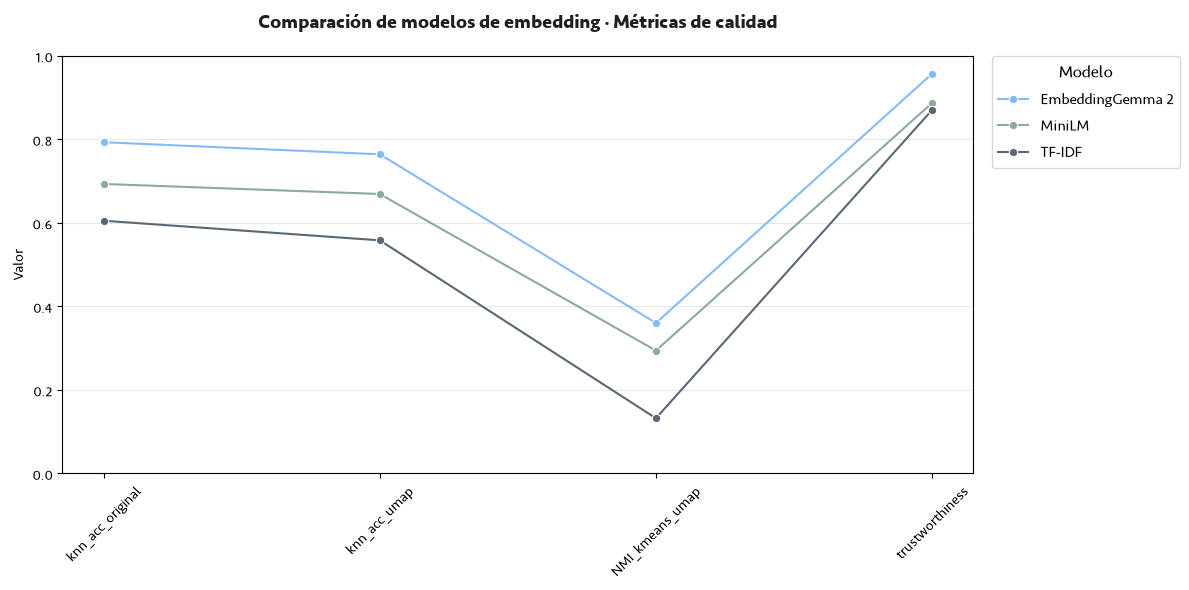

In [44]:
metric_cols = [
    col for col in models_data.columns
    if col not in ["modelo", "dims"]
]

colors = {
    "TF-IDF": "#5a6776",
    "MiniLM": "#8aaa9f",
    "EmbeddingGemma 2": "#82bbfd",
}

plot_data = (
    models_data.groupby("modelo", as_index=False)[metric_cols]
    .mean()
    .melt(
        id_vars="modelo",
        value_vars=metric_cols,
        var_name="metrica",
        value_name="valor",
    )
)

fig, ax = plt.subplots(figsize=(12, 6), facecolor="white")

sns.lineplot(
    data=plot_data,
    x="metrica",
    y="valor",
    hue="modelo",       # Columna que identifica cada línea
    palette=colors,     # Diccionario modelo -> color
    marker="o",
    errorbar=None,
    ax=ax,
)

ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Valor")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(
    title="Modelo",
    title_fontsize=12,
    fontsize=11,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
)
ax.set_title("Comparación de modelos de embedding · Métricas de calidad", fontsize=14, fontweight="bold", color="#1f1f1e", pad=20)
plt.tight_layout()
fig.savefig("informe/figs/metricas_modelos.png", dpi=200, bbox_inches="tight")
plt.show()